# 🐝 BeeSafe AI — Notebook 02: Chemical Identity Audit

### Goal
Identify potentially duplicated or inconsistent chemical identifiers **before** building ML features. We will compare PubChem CID, CAS, original SMILES, RDKit-canonicalized SMILES, and toxicity labels.


## 1. Import packages and set paths

Uses your existing Python installation. You do not need to create a new Conda environment. For your Windows PC, it uses the project location you established on `E:`. If the folder moves, edit `DEFAULT_PROJECT_ROOT`.

In [1]:
import os
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem.MolStandardize import rdMolStandardize

DEFAULT_PROJECT_ROOT = Path(
    r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI"
)
# Optional override only for portability/testing, not required on Windows:
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_PROJECT_ROOT)))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
AUDIT_DIR = PROJECT_ROOT / "reports" / "chemical_identity_audit"
FIGURE_DIR = AUDIT_DIR / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

print("RDKit:", rdBase.rdkitVersion)
print("Project folder exists:", PROJECT_ROOT.exists())
print("Source file exists:", DATA_PATH.is_file())
print("Reports will be saved to:", AUDIT_DIR)

RDKit: 2026.09.1
Project folder exists: True
Source file exists: True
Reports will be saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit


## 2. Load and validate the expected ApisTox columns

We add `source_row_index` as a stable **zero-based location within this file** to make it easy to find suspicious records later. Original 13 columns remain intact.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cannot find ApisTox CSV at: {DATA_PATH}")

original_df = pd.read_csv(DATA_PATH)
required = {
    "name", "CID", "CAS", "SMILES", "source", "year",
    "toxicity_type", "herbicide", "fungicide", "insecticide",
    "other_agrochemical", "label", "ppdb_level"
}
missing_columns = sorted(required.difference(original_df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

work = original_df.copy()
work.insert(0, "source_row_index", np.arange(len(work)))

print("Original dataset shape:", original_df.shape)
print("Missing cells:", int(original_df.isna().sum().sum()))
print("Exact duplicate rows:", int(original_df.duplicated().sum()))
display(original_df.head(3))

Original dataset shape: (1035, 13)
Missing cells: 0
Exact duplicate rows: 0


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0


## 3. Initial duplicate-identifier checks

The duplicate count from `.duplicated().sum()` means **extra occurrences**, not the number of all rows involved. `keep=False` returns **every row** belonging to a repeated group.

In [3]:
for field in ["CID", "CAS", "SMILES"]:
    repeated = work[field].duplicated(keep=False)
    print(f"{field}: repeated extra occurrences = {work[field].duplicated().sum():,}")
    print(f"{field}: rows involved in repeated groups = {repeated.sum():,}")
    print(f"{field}: unique repeated identifiers = {work.loc[repeated, field].nunique():,}")
    print("-" * 55)

cid_original_view = work.loc[
    work["CID"].duplicated(keep=False),
    ["source_row_index", "name", "CID", "CAS", "SMILES", "source", "label", "ppdb_level"]
].sort_values(["CID", "source_row_index"])
print("ALL rows belonging to repeated CID groups:")
display(cid_original_view)

CID: repeated extra occurrences = 5
CID: rows involved in repeated groups = 10
CID: unique repeated identifiers = 5
-------------------------------------------------------
CAS: repeated extra occurrences = 0
CAS: rows involved in repeated groups = 0
CAS: unique repeated identifiers = 0
-------------------------------------------------------
SMILES: repeated extra occurrences = 0
SMILES: rows involved in repeated groups = 0
SMILES: unique repeated identifiers = 0
-------------------------------------------------------
ALL rows belonging to repeated CID groups:


,source_row_index,name,CID,CAS,SMILES,source,label,ppdb_level
290,290,Chlormequat,13836,7003-89-6,C[N+](C)(C)CCCl,PPDB,0,1
295,295,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",13836,999-81-5,C[N+](C)(C)CCCl.[Cl-],ECOTOX,0,1
413,413,Silthiofam (Ref: MON 65500),16116,175217-20-6,C=CCNC(=O)c1c([Si](C)(C)C)sc(C)c1C,PPDB,0,1
416,416,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,1982-49-6,CC1CCCCC1NC(=O)Nc1ccccc1,ECOTOX,0,0
670,670,Diclomezine (Ref: F-850),93341,62865-36-5,Cc1c(Cl)cc(-c2ccc(=O)[nH]n2)cc1Cl,PPDB,0,1
672,672,Diflumetorim (Ref: UBF 002),93341,130339-07-0,CCC(Nc1ncnc(C)c1Cl)c1ccc(OC(F)F)cc1,PPDB,1,1
323,323,Metiram (Ref: BAS 222F),5284484,9006-42-2,S=C([S-])NCCNC(=S)S.S=C([S-])NCCNC(=S)S.[NH2-].[Zn],PPDB,0,1
328,328,Zineb (Ref: ENT 14874),5284484,12122-67-7,S=C([S-])NCCNC(=S)[S-].[Zn+2],PPDB,1,1
824,824,Metominostrobin (Ref: SSF 126),5483872,133408-50-1,CNC(=O)C(=NOC)c1ccccc1Oc1ccccc1,PPDB,0,1
832,832,Phthalide (Ref: BAY 96610),5483872,27355-22-2,O=C1OCc2c(Cl)c(Cl)c(Cl)c(Cl)c21,PPDB,0,0


## 4. Parse SMILES and calculate structure-comparison representations

**Canonical SMILES** normalize RDKit's notation while preserving stereochemistry (`isomericSmiles=True`).  
**Largest fragment** is an **audit hint only**; it can show whether two records differ by counterions, but may omit chemically meaningful components. **We will not use it to replace source structures or collapse compounds.**

In [4]:
chooser = rdMolStandardize.LargestFragmentChooser(preferOrganic=False)

def describe_smiles(text):
    result = {
        "valid_smiles": False,
        "canonical_smiles": None,
        "largest_fragment_smiles": None,
        "fragment_count": None,
    }
    if not isinstance(text, str) or not text.strip():
        return result
    try:
        mol = Chem.MolFromSmiles(text)
        if mol is None:
            return result
        result["valid_smiles"] = True
        result["canonical_smiles"] = Chem.MolToSmiles(mol, isomericSmiles=True)
        result["fragment_count"] = len(Chem.GetMolFrags(mol))
        largest = chooser.choose(mol)
        result["largest_fragment_smiles"] = Chem.MolToSmiles(
            largest, isomericSmiles=True
        )
    except Exception:
        return result
    return result

structure_data = work["SMILES"].apply(describe_smiles).apply(pd.Series)
audit = pd.concat([work, structure_data], axis=1)

print("Valid SMILES:", int(audit["valid_smiles"].sum()))
print("Invalid SMILES:", int((~audit["valid_smiles"]).sum()))
print("Number of distinct canonical structures:", audit["canonical_smiles"].nunique())
print("Exact canonical repetitions:", audit["canonical_smiles"].dropna().duplicated().sum())

display(audit[[
    "name", "CID", "CAS", "SMILES", "canonical_smiles",
    "largest_fragment_smiles", "fragment_count", "valid_smiles"
]].head(5))

[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Fragment: O=C([O-])[O-]
[11:19:32] New largest fragment: O=C([O-])[O-] (4)
[11:19:32] Fragment: [Ca+2]
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Fragment: [I-]
[11:19:32] New largest fragment: [I-] (1)
[11:19:32] Fragment: [K+]
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Running LargestFragmentChooser
[11:19:32] Fragment: N#C[S-]
[11:19:32] New largest fragment: N#C[S-] (3)
[11:19:32] Fragment: [K+]
[11:19:32] Running LargestFragmentChooser
[11:19:32] Fragment: O=S(=O)([O-])[O-]
[11:19:32] New largest fragment: O=S(=O)([O-])[O-] (5)
[11:19:32]

Valid SMILES: 1035
Invalid SMILES: 0
Number of distinct canonical structures: 1035
Exact canonical repetitions: 0


,name,CID,CAS,SMILES,canonical_smiles,largest_fragment_smiles,fragment_count,valid_smiles
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,O=C(O)C(=O)O,O=C(O)C(=O)O,1,True
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,1,True
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,O=[Si]=O,O=[Si]=O,1,True
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,O=C(O)c1ccccc1,O=C(O)c1ccccc1,1,True
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,1,True


## 5. Compare records sharing the same CID

Each CID group is evaluated **pair by pair**:

- `same_canonical_structure`: exact isomeric canonical form matches.
- `same_largest_fragment_only`: largest fragment matches but full structure differs (often a salt/counterion question; **not proof** of same compound).
- `different_structures`: even the largest-fragment forms differ.

This is a screening classification for manual review, **not PubChem verification**.

In [5]:
comparison_rows = []
for cid, group in audit.groupby("CID", dropna=False):
    if len(group) < 2:
        continue
    for (_, a), (_, b) in combinations(group.iterrows(), 2):
        same_canonical = (
            pd.notna(a["canonical_smiles"])
            and a["canonical_smiles"] == b["canonical_smiles"]
        )
        same_largest = (
            pd.notna(a["largest_fragment_smiles"])
            and a["largest_fragment_smiles"] == b["largest_fragment_smiles"]
        )
        if same_canonical:
            structural_relation = "same_canonical_structure"
        elif same_largest:
            structural_relation = "same_largest_fragment_only"
        else:
            structural_relation = "different_structures"

        comparison_rows.append({
            "CID": cid,
            "row_a": a["source_row_index"],
            "name_a": a["name"],
            "CAS_a": a["CAS"],
            "SMILES_a": a["SMILES"],
            "label_a": a["label"],
            "row_b": b["source_row_index"],
            "name_b": b["name"],
            "CAS_b": b["CAS"],
            "SMILES_b": b["SMILES"],
            "label_b": b["label"],
            "structural_relation": structural_relation,
            "labels_disagree": a["label"] != b["label"],
            "ppdb_levels_disagree": a["ppdb_level"] != b["ppdb_level"],
            "CAS_disagree": str(a["CAS"]) != str(b["CAS"]),
        })

cid_pairs = pd.DataFrame(comparison_rows)
print("Repeated CID groups:", int((audit.groupby("CID").size() > 1).sum()))
print("Number of same-CID pairs:", len(cid_pairs))
if not cid_pairs.empty:
    display(cid_pairs[[
        "CID", "name_a", "name_b", "structural_relation",
        "labels_disagree", "ppdb_levels_disagree", "CAS_disagree"
    ]])
    print("Pair relationships:")
    display(cid_pairs["structural_relation"].value_counts().to_frame("pairs"))
else:
    print("No CID pairs to review.")

Repeated CID groups: 5
Number of same-CID pairs: 5


,CID,name_a,name_b,structural_relation,labels_disagree,ppdb_levels_disagree,CAS_disagree
0,13836,Chlormequat,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",same_largest_fragment_only,False,False,True
1,16116,Silthiofam (Ref: MON 65500),N-(2-Methylcyclohexyl)-N'-phenylurea,different_structures,False,True,True
2,93341,Diclomezine (Ref: F-850),Diflumetorim (Ref: UBF 002),different_structures,True,False,True
3,5284484,Metiram (Ref: BAS 222F),Zineb (Ref: ENT 14874),different_structures,True,False,True
4,5483872,Metominostrobin (Ref: SSF 126),Phthalide (Ref: BAY 96610),different_structures,False,True,True


Pair relationships:


,pairs
structural_relation,
different_structures,4
same_largest_fragment_only,1


## 6. Find conflicting labels within identifiers and structures

We compare `label` and `ppdb_level` across shared identifiers and shared **canonical structures**. A label disagreement warrants investigation, but could reflect experimental endpoint differences—not necessarily an error.

In [6]:
def conflicting_groups(data, key, target):
    valid = data.dropna(subset=[key]).copy()
    nunique = valid.groupby(key)[target].nunique(dropna=True)
    conflict_ids = nunique[nunique > 1].index
    return valid.loc[valid[key].isin(conflict_ids)].sort_values(key)

checks = [
    ("CID", "label"),
    ("CID", "ppdb_level"),
    ("CAS", "label"),
    ("canonical_smiles", "label"),
    ("canonical_smiles", "ppdb_level"),
]
conflict_results = {}
for key, target in checks:
    keyname = f"{key}__{target}"
    frame = conflicting_groups(audit, key, target)
    conflict_results[keyname] = frame
    print(f"{key} → conflicting {target}: {frame[key].nunique()} groups / {len(frame)} rows")

print("\nCID groups with differing binary toxicity labels:")
display(conflict_results["CID__label"][[
    "source_row_index", "name", "CID", "CAS", "label", "ppdb_level"
]])

CID → conflicting label: 2 groups / 4 rows
CID → conflicting ppdb_level: 2 groups / 4 rows
CAS → conflicting label: 0 groups / 0 rows
canonical_smiles → conflicting label: 0 groups / 0 rows
canonical_smiles → conflicting ppdb_level: 0 groups / 0 rows

CID groups with differing binary toxicity labels:


,source_row_index,name,CID,CAS,label,ppdb_level
672,672,Diflumetorim (Ref: UBF 002),93341,130339-07-0,1,1
670,670,Diclomezine (Ref: F-850),93341,62865-36-5,0,1
328,328,Zineb (Ref: ENT 14874),5284484,12122-67-7,1,1
323,323,Metiram (Ref: BAS 222F),5284484,9006-42-2,0,1


## 7. Audit chemical structures independent of CID

This is important because **different identifiers could point to the same exact structure**. Conversely, distinct salts or fragments may share a largest component without being interchangeable.

**We do not deduplicate based on largest fragments.**

In [7]:
canonical_repeated = audit.loc[
    audit["canonical_smiles"].notna()
    & audit["canonical_smiles"].duplicated(keep=False)
].sort_values("canonical_smiles")

cas_repeated = audit.loc[
    audit["CAS"].notna() & audit["CAS"].duplicated(keep=False)
].sort_values("CAS")

largest_repeated = audit.loc[
    audit["largest_fragment_smiles"].notna()
    & audit["largest_fragment_smiles"].duplicated(keep=False)
]

print("Rows with repeated canonical SMILES:", len(canonical_repeated))
print("Rows with repeated CAS:", len(cas_repeated))
print("Rows sharing a largest fragment:", len(largest_repeated))
print("Note: sharing a largest fragment DOES NOT imply identical compounds.")

print("\nRepeated canonical structures (if any):")
display(canonical_repeated[[
    "source_row_index", "name", "CID", "CAS", "canonical_smiles", "label"
]].head(30))

Rows with repeated canonical SMILES: 0
Rows with repeated CAS: 0
Rows sharing a largest fragment: 86
Note: sharing a largest fragment DOES NOT imply identical compounds.

Repeated canonical structures (if any):


,source_row_index,name,CID,CAS,canonical_smiles,label


## 8. Build transparent audit flags (no automatic changes)

A record receives a flag when (a) CID is repeated with multiple canonical structures, (b) its CID group has inconsistent labels, (c) the CAS is repeated across multiple canonical structures, (d) its exact canonical structure has conflicting labels, or (e) SMILES is invalid.

`review_priority` is **our workflow priority**, not a scientific risk score. Every repeated CID is queued for human review, including cases that differ only by a counterion.

In [8]:
audit["cid_repeated"] = audit["CID"].duplicated(keep=False)
audit["cas_repeated"] = audit["CAS"].duplicated(keep=False)
audit["canonical_repeated"] = (
    audit["canonical_smiles"].notna()
    & audit["canonical_smiles"].duplicated(keep=False)
)

cid_structure_n = audit.groupby("CID")["canonical_smiles"].nunique(dropna=True)
cid_label_n = audit.groupby("CID")["label"].nunique(dropna=True)
cas_structure_n = audit.groupby("CAS")["canonical_smiles"].nunique(dropna=True)
canonical_label_n = audit.dropna(subset=["canonical_smiles"]).groupby(
    "canonical_smiles"
)["label"].nunique(dropna=True)

audit["cid_multiple_structures"] = audit["CID"].map(cid_structure_n).fillna(0).gt(1)
audit["cid_conflicting_labels"] = audit["CID"].map(cid_label_n).fillna(0).gt(1)
audit["cas_multiple_structures"] = audit["CAS"].map(cas_structure_n).fillna(0).gt(1)
audit["canonical_conflicting_labels"] = audit["canonical_smiles"].map(
    canonical_label_n
).fillna(0).gt(1)

flag_columns = [
    "cid_repeated", "cid_multiple_structures", "cid_conflicting_labels",
    "cas_multiple_structures", "canonical_conflicting_labels",
]

def describe_flags(row):
    flags = [col for col in flag_columns if bool(row[col])]
    if not bool(row["valid_smiles"]):
        flags.append("invalid_smiles")
    return "; ".join(flags)

audit["issue_flags"] = audit.apply(describe_flags, axis=1)
audit["needs_review"] = audit["issue_flags"].str.len().gt(0)
audit["review_priority"] = np.select(
    [
        (~audit["valid_smiles"]) | audit["cid_conflicting_labels"]
        | audit["cas_multiple_structures"] | audit["canonical_conflicting_labels"],
        audit["cid_multiple_structures"] | audit["cid_repeated"],
    ],
    ["HIGH", "MEDIUM"],
    default="NONE",
)

review_queue = audit.loc[audit["needs_review"]].sort_values(
    by=["CID", "source_row_index"]
).copy()

print("Total flagged records:", len(review_queue))
print("Review priorities:")
display(audit["review_priority"].value_counts().to_frame("records"))
display(review_queue[[
    "source_row_index", "name", "CID", "CAS", "label", "ppdb_level",
    "issue_flags", "review_priority"
]])

Total flagged records: 10
Review priorities:


,records
review_priority,
NONE,1025
MEDIUM,6
HIGH,4


,source_row_index,name,CID,CAS,label,ppdb_level,issue_flags,review_priority
290,290,Chlormequat,13836,7003-89-6,0,1,cid_repeated; cid_multiple_structures,MEDIUM
295,295,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",13836,999-81-5,0,1,cid_repeated; cid_multiple_structures,MEDIUM
413,413,Silthiofam (Ref: MON 65500),16116,175217-20-6,0,1,cid_repeated; cid_multiple_structures,MEDIUM
416,416,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,1982-49-6,0,0,cid_repeated; cid_multiple_structures,MEDIUM
670,670,Diclomezine (Ref: F-850),93341,62865-36-5,0,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
672,672,Diflumetorim (Ref: UBF 002),93341,130339-07-0,1,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
323,323,Metiram (Ref: BAS 222F),5284484,9006-42-2,0,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
328,328,Zineb (Ref: ENT 14874),5284484,12122-67-7,1,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
824,824,Metominostrobin (Ref: SSF 126),5483872,133408-50-1,0,1,cid_repeated; cid_multiple_structures,MEDIUM
832,832,Phthalide (Ref: BAY 96610),5483872,27355-22-2,0,0,cid_repeated; cid_multiple_structures,MEDIUM


## 9. Visual summary of audit findings

This visualization counts **records carrying each flag**. Categories overlap, so bars **must not be summed** to obtain a unique record count.

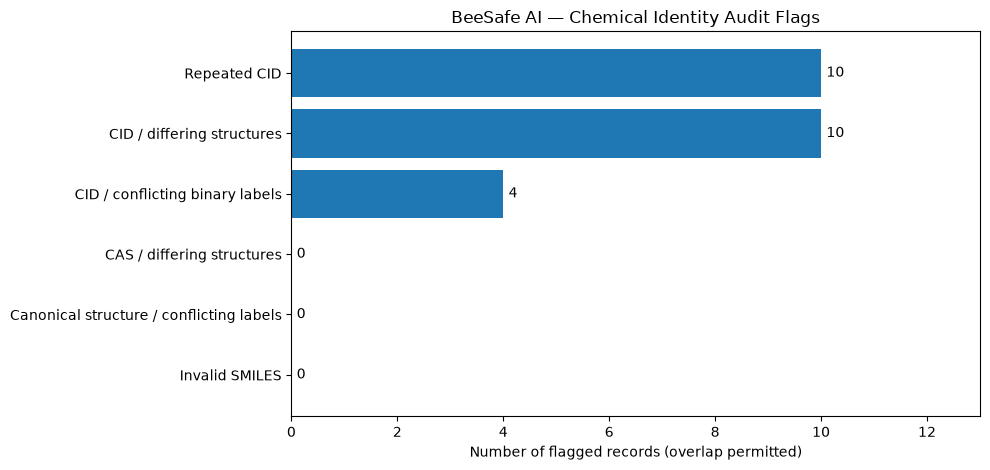

Saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\figures\identity_audit_flags.png


In [9]:
plot_flags = {
    "Repeated CID": int(audit["cid_repeated"].sum()),
    "CID / differing structures": int(audit["cid_multiple_structures"].sum()),
    "CID / conflicting binary labels": int(audit["cid_conflicting_labels"].sum()),
    "CAS / differing structures": int(audit["cas_multiple_structures"].sum()),
    "Canonical structure / conflicting labels": int(audit["canonical_conflicting_labels"].sum()),
    "Invalid SMILES": int((~audit["valid_smiles"]).sum()),
}

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(list(plot_flags.keys()), list(plot_flags.values()))
ax.invert_yaxis()
ax.set_title("BeeSafe AI — Chemical Identity Audit Flags")
ax.set_xlabel("Number of flagged records (overlap permitted)")
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, f"{int(width)}", va="center")
ax.set_xlim(0, max(plot_flags.values(), default=0) + 3)
fig.tight_layout()
chart_path = FIGURE_DIR / "identity_audit_flags.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", chart_path)

## 10. Export all reports and a manual verification worksheet

### Files generated
- `chemical_identity_audit_full.csv`: all source records, plus **non-destructive** audit columns.
- `repeated_cid_records.csv`: every record associated with a repeated CID.
- `repeated_cid_pairs.csv`: comparisons of those pairs.
- `repeated_cas_records.csv` and `repeated_canonical_records.csv`: independent structure checks.
- `identity_review_queue.csv`: records requiring review.
- `manual_verification_template.csv`: worksheet for checking authoritative identifiers with evidence. Do **not** assume the references are already verified.
- `audit_summary.json`: machine-readable counts.

The manual verification worksheet includes blank fields for recording official evidence (for example, PubChem identity, data-source documentation, registry records). **This notebook does not access PubChem, call external APIs, or certify any identity.**

In [10]:
# Full, transparent audit — do not replace original raw dataset
saved_files = {}

def save_csv(frame, filename):
    path = AUDIT_DIR / filename
    frame.to_csv(path, index=False)
    saved_files[filename] = str(path)

def safe_subset_by_repeated(frame, column):
    return frame.loc[frame[column].notna() & frame[column].duplicated(keep=False)]

save_csv(audit, "chemical_identity_audit_full.csv")
save_csv(audit.loc[audit["cid_repeated"]], "repeated_cid_records.csv")
save_csv(cid_pairs, "repeated_cid_pairs.csv")
save_csv(cas_repeated, "repeated_cas_records.csv")
save_csv(canonical_repeated, "repeated_canonical_records.csv")
save_csv(review_queue, "identity_review_queue.csv")

manual_review = review_queue[[
    "source_row_index", "name", "CID", "CAS", "SMILES", "canonical_smiles",
    "label", "ppdb_level", "issue_flags", "review_priority"
]].copy()
manual_review["verification_status"] = "NOT_VERIFIED"
manual_review["authoritative_chemical_identity"] = ""
manual_review["verified_cid"] = ""
manual_review["verified_cas"] = ""
manual_review["evidence_source_url"] = ""
manual_review["review_notes"] = ""
manual_review["decision"] = "PENDING_REVIEW"
save_csv(manual_review, "manual_verification_template.csv")

summary = {
    "dataset_rows": int(len(original_df)),
    "dataset_original_columns": int(original_df.shape[1]),
    "missing_cells": int(original_df.isna().sum().sum()),
    "exact_duplicate_rows": int(original_df.duplicated().sum()),
    "valid_smiles": int(audit["valid_smiles"].sum()),
    "invalid_smiles": int((~audit["valid_smiles"]).sum()),
    "distinct_canonical_smiles": int(audit["canonical_smiles"].nunique()),
    "cid_repeated_rows": int(audit["cid_repeated"].sum()),
    "cid_repeated_groups": int((audit.groupby("CID").size() > 1).sum()),
    "cid_groups_with_binary_label_conflicts": int(
        (audit.groupby("CID")["label"].nunique() > 1).sum()
    ),
    "cas_repeated_rows": int(audit["cas_repeated"].sum()),
    "canonical_repeated_rows": int(audit["canonical_repeated"].sum()),
    "records_needing_manual_review": int(len(review_queue)),
    "priority_counts": {
        str(k): int(v) for k, v in audit["review_priority"].value_counts().items()
    },
    "interpretation": "Structural comparisons are screening flags, not verified identity corrections.",
}
summary_path = AUDIT_DIR / "audit_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
saved_files["audit_summary.json"] = str(summary_path)

print("Reports saved successfully!")
for filename in saved_files:
    print(" -", filename)
print(" - figures/identity_audit_flags.png")

Reports saved successfully!
 - chemical_identity_audit_full.csv
 - repeated_cid_records.csv
 - repeated_cid_pairs.csv
 - repeated_cas_records.csv
 - repeated_canonical_records.csv
 - identity_review_queue.csv
 - manual_verification_template.csv
 - audit_summary.json
 - figures/identity_audit_flags.png


## 11. Final review and decision gate

**Do not modify or drop rows yet.** The results help prioritize which records to check against official data. We will create a documented cleaning decision in a later notebook **only after** the manual verification is complete.

### What needs review before ML?
1. For every repeated CID, confirm whether PubChem and each source database associate it with the same entity.
2. Compare CAS, molecular structure, salts/counterions, stereochemistry and original source references.
3. Where toxicity labels disagree, investigate whether the rows refer to different compounds **or** different experimental endpoints/measurements.
4. Preserve a traceable decision log; never silently overwrite source IDs or labels.
5. Maintain the authors' predefined train/test splits in later ML experiments to avoid inadvertently changing their benchmark; check overlaps by canonical structure after splitting.

**GitHub note:** Keep the raw dataset, full audit CSVs, and derived records local until redistribution rights have been verified. Code, documentation, and non-sensitive aggregate audit summaries can be committed under appropriate terms.

In [11]:
print("=" * 65)
print("BEESAFE AI — CHEMICAL IDENTITY AUDIT FINISHED")
print("=" * 65)
for key, value in summary.items():
    print(f"{key}: {value}")

# Guardrail: this audit must not alter the original source dataframe.
assert len(original_df) == len(audit)
assert list(original_df.columns) == list(pd.read_csv(DATA_PATH).columns)
assert original_df.equals(pd.read_csv(DATA_PATH))
print("\nOriginal dataset integrity: unchanged ✅")
print("Manual verification required before any identifier corrections.")

BEESAFE AI — CHEMICAL IDENTITY AUDIT FINISHED
dataset_rows: 1035
dataset_original_columns: 13
missing_cells: 0
exact_duplicate_rows: 0
valid_smiles: 1035
invalid_smiles: 0
distinct_canonical_smiles: 1035
cid_repeated_rows: 10
cid_repeated_groups: 5
cid_groups_with_binary_label_conflicts: 2
cas_repeated_rows: 0
canonical_repeated_rows: 0
records_needing_manual_review: 10
priority_counts: {'NONE': 1025, 'MEDIUM': 6, 'HIGH': 4}
interpretation: Structural comparisons are screening flags, not verified identity corrections.

Original dataset integrity: unchanged ✅
Manual verification required before any identifier corrections.
